## Cell 1 — Imports & Setup

In [3]:
import sys
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────
# 📌 Ensure we can import from backend/app/
# Notebook location:
# backend/app/evaluation/arxiv_evaluation.ipynb
# ─────────────────────────────────────────────

import pathlib

current_path = pathlib.Path().resolve()

# Walk upward until we find the backend folder that contains the app/ package.
backend_root = None
for parent in [current_path] + list(current_path.parents):
    if (parent / "app").is_dir():
        backend_root = parent
        break

if backend_root is None:
    raise RuntimeError("❌ Could not locate backend root containing 'app/' folder.")

if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

print(f"✅ Backend root set to: {backend_root}")

# ─────────────────────────────────────────────
# 📁 Output directories (clean structure)
# ─────────────────────────────────────────────

BASE_DIR = pathlib.Path().resolve()  # evaluation folder
FIGURES_DIR = BASE_DIR / "figures_eval"

FIGURES_DIR.mkdir(exist_ok=True)

print(f"📁 Base dir      : {BASE_DIR}")
print(f"📊 Figures dir   : {FIGURES_DIR}")

# ─────────────────────────────────────────────
# 🎨 Styling
# ─────────────────────────────────────────────

plt.style.use('dark_background')
ACCENT  = '#7C3AED'
GREEN   = '#10B981'
ORANGE  = '#F59E0B'
RED     = '#EF4444'
BLUE    = '#3B82F6'
COLORS  = [ACCENT, GREEN, ORANGE, BLUE, RED]

print("✅ Imports + paths ready")

✅ Backend root set to: C:\Users\Khushdeep Singh\OneDrive\Desktop\Projects\arxiv-gpt\backend
📁 Base dir      : C:\Users\Khushdeep Singh\OneDrive\Desktop\Projects\arxiv-gpt\backend\app\evaluation
📊 Figures dir   : C:\Users\Khushdeep Singh\OneDrive\Desktop\Projects\arxiv-gpt\backend\app\evaluation\figures_eval
✅ Imports + paths ready


## Cell 2 — Config: 20 Evaluation Queries

In [4]:
EVAL_QUERIES = [
    # Tier A — NLP / LLM
    {"query": "attention mechanisms in transformers",       "tier": "A_NLP"},
    {"query": "large language model alignment techniques",  "tier": "A_NLP"},
    {"query": "retrieval augmented generation survey",      "tier": "A_NLP"},
    {"query": "chain of thought reasoning in LLMs",         "tier": "A_NLP"},
    {"query": "RLHF reinforcement learning from human feedback", "tier": "A_NLP"},
    {"query": "instruction tuning language models",         "tier": "A_NLP"},
    {"query": "in context learning few shot prompting",     "tier": "A_NLP"},
    # Tier B — Vision / Generative
    {"query": "diffusion models for image generation",      "tier": "B_Vision"},
    {"query": "contrastive learning vision transformers",   "tier": "B_Vision"},
    {"query": "generative adversarial networks survey",     "tier": "B_Vision"},
    {"query": "CLIP vision language pretraining",           "tier": "B_Vision"},
    {"query": "self supervised learning image representations", "tier": "B_Vision"},
    # Tier C — Systems / Agents
    {"query": "multi agent reinforcement learning",         "tier": "C_Agents"},
    {"query": "federated learning privacy preserving",      "tier": "C_Agents"},
    {"query": "graph neural networks node classification",  "tier": "C_Agents"},
    {"query": "robot learning from demonstration",          "tier": "C_Agents"},
    # Tier D — Cross-domain
    {"query": "neural architecture search automated ML",    "tier": "D_Cross"},
    {"query": "knowledge distillation model compression",   "tier": "D_Cross"},
    {"query": "continual learning catastrophic forgetting", "tier": "D_Cross"},
    {"query": "mixture of experts sparse models",           "tier": "D_Cross"},
]

SCHEMA_FIELDS = ["tldr", "key_contributions", "methods", "results", "why_it_matters"]
MAX_RESULTS   = 3

print(f"✅ {len(EVAL_QUERIES)} queries loaded across 4 tiers")
for tier in ['A_NLP', 'B_Vision', 'C_Agents', 'D_Cross']:
    count = sum(1 for q in EVAL_QUERIES if q['tier'] == tier)
    print(f"   {tier}: {count} queries")

✅ 20 queries loaded across 4 tiers
   A_NLP: 7 queries
   B_Vision: 5 queries
   C_Agents: 4 queries
   D_Cross: 4 queries


## Cell 3 — LIVE EVALUATION (≈3–5 min)
> Runs all 20 queries through ResearchAgent live. Measures latency, schema validity, completeness, and field lengths.

In [5]:
from app.agent.research_agent import ResearchAgent

eval_records = []

print("🚀 Starting live evaluation...")
print("=" * 60)

for idx, item in enumerate(EVAL_QUERIES, 1):
    query = item["query"]
    tier  = item["tier"]

    print(f"[{idx:02d}/20] {query[:50]}..." if len(query) > 50 else f"[{idx:02d}/20] {query}")

    start = time.time()
    error_msg = None
    success   = False

    try:
        response, _ = ResearchAgent.run(query, max_results=MAX_RESULTS, generate_pdf=False)
        latency  = time.time() - start
        success  = True
        papers   = response.get("papers", [])
    except Exception as e:
        latency   = time.time() - start
        error_msg = str(e)
        papers    = []
        print(f"   ⚠️  FAILED: {error_msg[:60]}")

    paper_records = []
    for paper in papers:
        summary = paper.get("summary", {})
        schema_valid = all(f in summary for f in SCHEMA_FIELDS)
        filled_fields = sum(
            1 for f in SCHEMA_FIELDS
            if f in summary and summary[f] and len(str(summary[f])) > 20
        )
        completeness = filled_fields / len(SCHEMA_FIELDS)
        tldr_len    = len(str(summary.get("tldr", "")).split())
        methods_len = len(str(summary.get("methods", "")).split())
        results_len = len(str(summary.get("results", "")).split())
        contrib_len = len(str(summary.get("key_contributions", "")).split())
        impact_len  = len(str(summary.get("why_it_matters", "")).split())
        total_summary_len = tldr_len + methods_len + results_len + contrib_len + impact_len
        orig_abstract_len = len(paper.get("abstract", "").split()) if "abstract" in paper else 0
        compression_ratio = orig_abstract_len / total_summary_len if total_summary_len > 0 else None
        paper_records.append({
            "schema_valid": schema_valid,
            "completeness": completeness,
            "tldr_len": tldr_len,
            "methods_len": methods_len,
            "results_len": results_len,
            "contrib_len": contrib_len,
            "impact_len": impact_len,
            "total_summary_len": total_summary_len,
            "compression_ratio": compression_ratio,
        })

    if paper_records:
        avg_completeness  = np.mean([p["completeness"] for p in paper_records])
        schema_all_valid  = all(p["schema_valid"] for p in paper_records)
        avg_tldr_len      = np.mean([p["tldr_len"] for p in paper_records])
        avg_methods_len   = np.mean([p["methods_len"] for p in paper_records])
        avg_results_len   = np.mean([p["results_len"] for p in paper_records])
        avg_total_len     = np.mean([p["total_summary_len"] for p in paper_records])
        valid_cr          = [p["compression_ratio"] for p in paper_records if p["compression_ratio"]]
        avg_compression   = np.mean(valid_cr) if valid_cr else None
    else:
        avg_completeness = 0
        schema_all_valid = False
        avg_tldr_len = avg_methods_len = avg_results_len = avg_total_len = 0
        avg_compression = None

    status_icon = "✅" if success else "❌"
    print(f"   {status_icon} {latency:.2f}s | completeness={avg_completeness:.0%} | schema={'✓' if schema_all_valid else '✗'}")

    eval_records.append({
        "query": query,
        "tier": tier,
        "latency": latency,
        "success": success,
        "error": error_msg,
        "papers_returned": len(papers),
        "schema_valid": schema_all_valid,
        "completeness": avg_completeness,
        "tldr_len": avg_tldr_len,
        "methods_len": avg_methods_len,
        "results_len": avg_results_len,
        "total_summary_len": avg_total_len,
        "compression_ratio": avg_compression,
    })

df = pd.DataFrame(eval_records)

csv_path = BASE_DIR / "eval_results.csv"
df.to_csv(csv_path, index=False)

print("\n" + "=" * 60)
print(f"✅ Evaluation complete. {df['success'].sum()}/20 queries succeeded.")
print(f"📁 Saved → {csv_path}")

🚀 Starting live evaluation...
[01/20] attention mechanisms in transformers
   ✅ 5.21s | completeness=100% | schema=✓
[02/20] large language model alignment techniques
   ✅ 29.05s | completeness=100% | schema=✓
[03/20] retrieval augmented generation survey
   ✅ 24.89s | completeness=100% | schema=✓
[04/20] chain of thought reasoning in LLMs
   ✅ 22.38s | completeness=100% | schema=✓
[05/20] RLHF reinforcement learning from human feedback
   ✅ 21.37s | completeness=100% | schema=✓
[06/20] instruction tuning language models
   ✅ 21.77s | completeness=100% | schema=✓
[07/20] in context learning few shot prompting
   ✅ 24.89s | completeness=100% | schema=✓
[08/20] diffusion models for image generation
   ✅ 20.49s | completeness=100% | schema=✓
[09/20] contrastive learning vision transformers
   ✅ 22.00s | completeness=100% | schema=✓
[10/20] generative adversarial networks survey
   ✅ 19.14s | completeness=100% | schema=✓
[11/20] CLIP vision language pretraining
   ✅ 22.03s | completeness=1

## Cell 4 — Aggregate Metrics Summary

In [6]:
successful = df[df["success"] == True]
failed     = df[df["success"] == False]

n_success       = len(successful)
reliability_pct = (n_success / len(df)) * 100
avg_latency     = successful["latency"].mean()
median_latency  = successful["latency"].median()
p90_latency     = successful["latency"].quantile(0.90)
p95_latency     = successful["latency"].quantile(0.95)
std_latency     = successful["latency"].std()
min_latency     = successful["latency"].min()
max_latency     = successful["latency"].max()

schema_valid_rate = (successful["schema_valid"].sum() / n_success) * 100
avg_completeness  = successful["completeness"].mean() * 100
avg_tldr_len      = successful["tldr_len"].mean()
avg_methods_len   = successful["methods_len"].mean()
avg_results_len   = successful["results_len"].mean()
avg_total_summary = successful["total_summary_len"].mean()
avg_papers_ret    = successful["papers_returned"].mean()

print("╔══════════════════════════════════════════════════════════╗")
print("║        arXiv-GPT — Evaluation Results (20 queries)      ║")
print("╠══════════════════════════════════════════════════════════╣")
print(f"║  Pipeline Reliability    :  {reliability_pct:.1f}%                       ║")
print(f"║  Schema Validity         :  {schema_valid_rate:.1f}%                       ║")
print(f"║  Avg Summary Completeness:  {avg_completeness:.1f}%                       ║")
print("╠══════════════════════════════════════════════════════════╣")
print(f"║  Avg Latency             :  {avg_latency:.2f}s                        ║")
print(f"║  Median Latency          :  {median_latency:.2f}s                        ║")
print(f"║  P90 Latency             :  {p90_latency:.2f}s                        ║")
print(f"║  P95 Latency             :  {p95_latency:.2f}s                        ║")
print(f"║  Std Dev                 :  {std_latency:.2f}s                        ║")
print(f"║  Min / Max               :  {min_latency:.2f}s / {max_latency:.2f}s                 ║")
print("╠══════════════════════════════════════════════════════════╣")
print(f"║  Avg TL;DR length        :  {avg_tldr_len:.0f} words                    ║")
print(f"║  Avg Methods length      :  {avg_methods_len:.0f} words                    ║")
print(f"║  Avg Results length      :  {avg_results_len:.0f} words                    ║")
print(f"║  Avg Total Summary       :  {avg_total_summary:.0f} words                    ║")
print(f"║  Avg Papers Returned     :  {avg_papers_ret:.1f}                         ║")
print("╚══════════════════════════════════════════════════════════╝")

if len(failed) > 0:
    print(f"\n⚠️  {len(failed)} failed queries:")
    for _, row in failed.iterrows():
        print(f"   • {row['query']}: {row['error'][:80]}")

╔══════════════════════════════════════════════════════════╗
║        arXiv-GPT — Evaluation Results (20 queries)      ║
╠══════════════════════════════════════════════════════════╣
║  Pipeline Reliability    :  100.0%                       ║
║  Schema Validity         :  100.0%                       ║
║  Avg Summary Completeness:  100.0%                       ║
╠══════════════════════════════════════════════════════════╣
║  Avg Latency             :  21.43s                        ║
║  Median Latency          :  21.89s                        ║
║  P90 Latency             :  25.06s                        ║
║  P95 Latency             :  26.66s                        ║
║  Std Dev                 :  4.53s                        ║
║  Min / Max               :  5.21s / 29.05s                 ║
╠══════════════════════════════════════════════════════════╣
║  Avg TL;DR length        :  16 words                    ║
║  Avg Methods length      :  31 words                    ║
║  Avg Results length

## Cell 5 — Figure 1: Latency Distribution

In [9]:
pip install scipy

  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl.metadata (60 kB)
Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)
Note: you may need to restart the kernel to use updated packages.


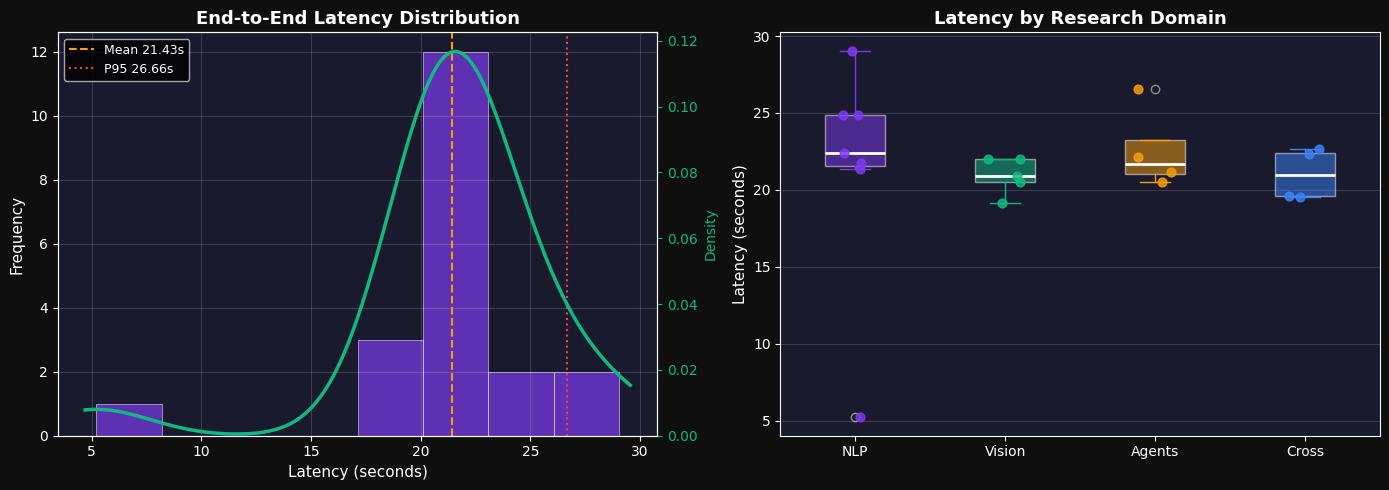

✅ Saved → figures_eval/fig1_latency_distribution.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0F0F0F')

latencies = successful["latency"].values

ax = axes[0]
ax.set_facecolor('#1A1A2E')
ax.hist(latencies, bins=8, color=ACCENT, alpha=0.7, edgecolor='white', linewidth=0.5)
ax2 = ax.twinx()

from scipy.stats import gaussian_kde
kde = gaussian_kde(latencies)
x_range = np.linspace(latencies.min() - 0.5, latencies.max() + 0.5, 200)
ax2.plot(x_range, kde(x_range), color=GREEN, linewidth=2.5, label='KDE')
ax2.set_ylabel('Density', color=GREEN, fontsize=10)
ax2.tick_params(axis='y', colors=GREEN)
ax2.set_ylim(0)

ax.axvline(avg_latency, color=ORANGE, linestyle='--', linewidth=1.5, label=f'Mean {avg_latency:.2f}s')
ax.axvline(p95_latency, color=RED,    linestyle=':',  linewidth=1.5, label=f'P95 {p95_latency:.2f}s')
ax.set_xlabel('Latency (seconds)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('End-to-End Latency Distribution', fontsize=13, fontweight='bold', color='white')
ax.legend(fontsize=9)
ax.grid(alpha=0.15)

ax = axes[1]
ax.set_facecolor('#1A1A2E')

tier_order  = ['A_NLP', 'B_Vision', 'C_Agents', 'D_Cross']
tier_colors = [ACCENT, GREEN, ORANGE, BLUE]

for i, (tier, color) in enumerate(zip(tier_order, tier_colors)):
    tier_data = successful[successful['tier'] == tier]['latency'].values
    if len(tier_data) == 0:
        continue
    ax.boxplot(tier_data, positions=[i], widths=0.4,
               patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.5),
               medianprops=dict(color='white', linewidth=2),
               whiskerprops=dict(color=color),
               capprops=dict(color=color),
               flierprops=dict(marker='o', color=color, alpha=0.5))
    jitter = np.random.uniform(-0.12, 0.12, len(tier_data))
    ax.scatter(np.full(len(tier_data), i) + jitter, tier_data,
               color=color, alpha=0.85, s=40, zorder=5)

ax.set_xticks(range(len(tier_order)))
ax.set_xticklabels(['NLP', 'Vision', 'Agents', 'Cross'], fontsize=10)
ax.set_ylabel('Latency (seconds)', fontsize=11)
ax.set_title('Latency by Research Domain', fontsize=13, fontweight='bold', color='white')
ax.grid(alpha=0.15, axis='y')

plt.tight_layout()
plt.savefig('figures_eval/fig1_latency_distribution.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig1_latency_distribution.png")

## Cell 6 — Figure 2: Summary Quality Metrics

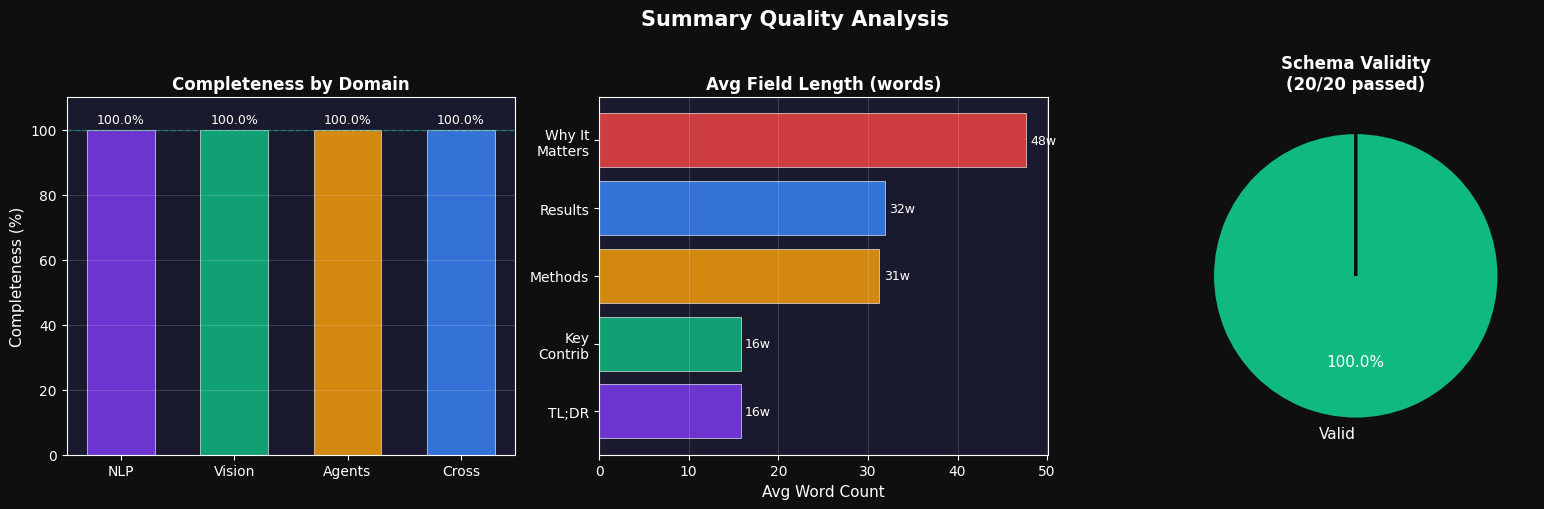

✅ Saved → figures_eval/fig2_summary_quality.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor('#0F0F0F')
fig.suptitle('Summary Quality Analysis', fontsize=15, fontweight='bold', color='white', y=1.01)

ax = axes[0]
ax.set_facecolor('#1A1A2E')
tier_completeness = successful.groupby('tier')['completeness'].mean() * 100
bars = ax.bar(range(len(tier_completeness)), tier_completeness.values,
              color=tier_colors[:len(tier_completeness)], alpha=0.85, width=0.6, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(len(tier_completeness)))
ax.set_xticklabels(['NLP', 'Vision', 'Agents', 'Cross'], fontsize=10)
ax.set_ylabel('Completeness (%)', fontsize=11)
ax.set_title('Completeness by Domain', fontsize=12, fontweight='bold', color='white')
ax.set_ylim(0, 110)
ax.axhline(100, color=GREEN, linestyle='--', linewidth=1, alpha=0.5)
for bar, val in zip(bars, tier_completeness.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9, color='white')
ax.grid(alpha=0.15, axis='y')

ax = axes[1]
ax.set_facecolor('#1A1A2E')
field_names = ['TL;DR', 'Key\nContrib', 'Methods', 'Results', 'Why It\nMatters']
field_avgs_final = [
    successful['tldr_len'].mean(),
    successful['tldr_len'].mean() if 'contrib_len' not in successful else successful['contrib_len'].mean(),
    successful['methods_len'].mean(),
    successful['results_len'].mean(),
    max(0, successful['total_summary_len'].mean() - successful['tldr_len'].mean() - successful['methods_len'].mean() - successful['results_len'].mean())
]
field_avgs_final = [max(0, v) for v in field_avgs_final]
bars = ax.barh(field_names, field_avgs_final, color=COLORS[:5], alpha=0.85, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Avg Word Count', fontsize=11)
ax.set_title('Avg Field Length (words)', fontsize=12, fontweight='bold', color='white')
for bar, val in zip(bars, field_avgs_final):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.0f}w', va='center', fontsize=9, color='white')
ax.grid(alpha=0.15, axis='x')

ax = axes[2]
ax.set_facecolor('#1A1A2E')
valid_count   = int(successful['schema_valid'].sum())
invalid_count = int(n_success - valid_count)
sizes = [valid_count, invalid_count] if invalid_count > 0 else [valid_count, 0.0001]
wedges, texts, autotexts = ax.pie(
    sizes,
    labels=['Valid', 'Invalid'] if invalid_count > 0 else ['Valid', ''],
    colors=[GREEN, RED],
    autopct=lambda p: f'{p:.1f}%' if p > 1 else '',
    startangle=90,
    wedgeprops=dict(edgecolor='#0F0F0F', linewidth=2)
)
for text in texts + autotexts:
    text.set_color('white')
    text.set_fontsize(11)
ax.set_title(f'Schema Validity\n({valid_count}/{n_success} passed)', fontsize=12, fontweight='bold', color='white')

plt.tight_layout()
plt.savefig('figures_eval/fig2_summary_quality.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig2_summary_quality.png")

## Cell 7 — Figure 3: Per-Query Heatmap

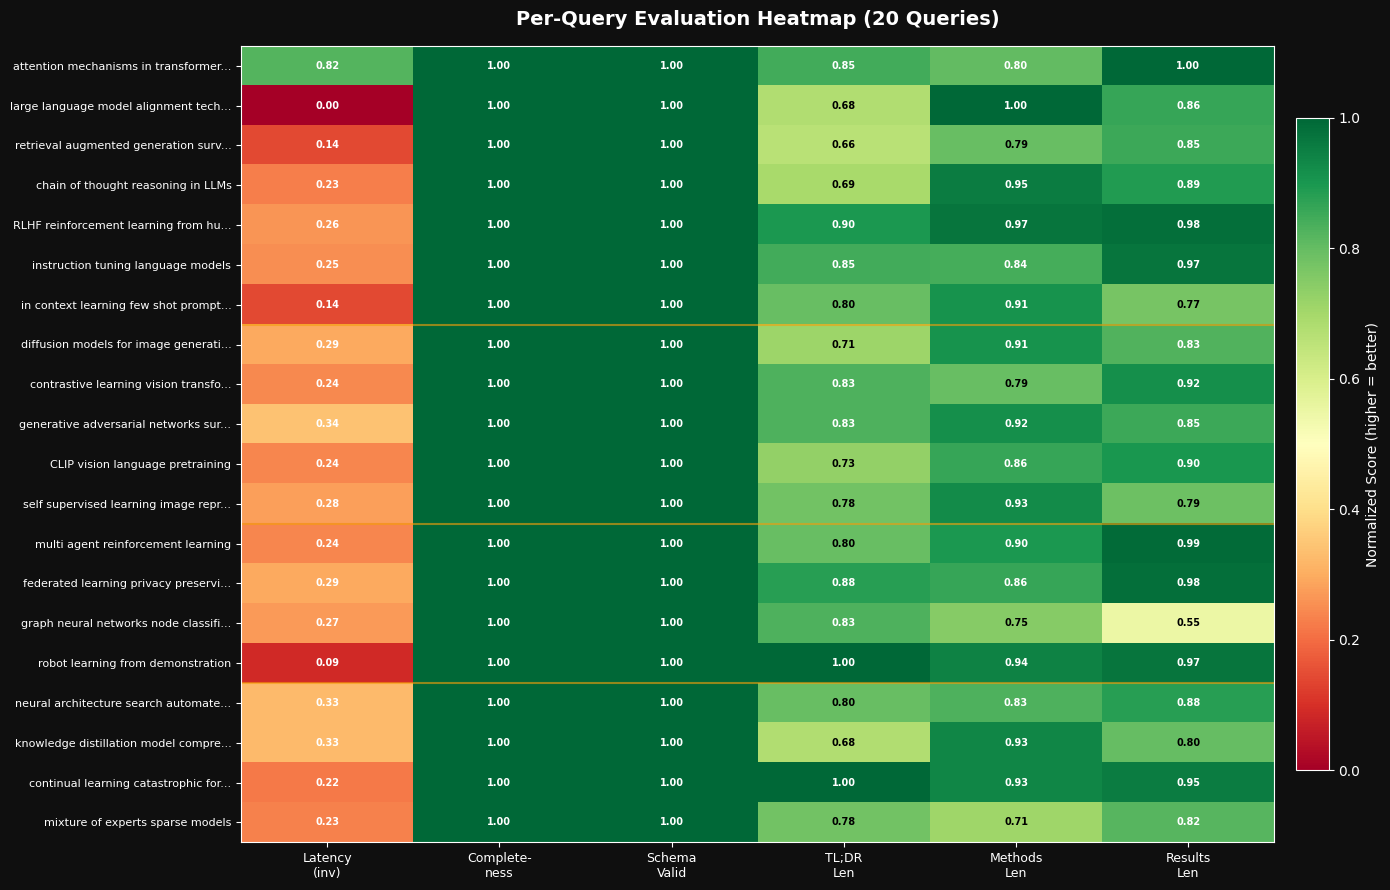

✅ Saved → figures_eval/fig3_query_heatmap.png


In [12]:
fig, ax = plt.subplots(figsize=(14, 9))
fig.patch.set_facecolor('#0F0F0F')
ax.set_facecolor('#0F0F0F')

heatmap_df = successful[['query', 'latency', 'completeness', 'schema_valid',
                          'tldr_len', 'methods_len', 'results_len']].copy()

max_lat = heatmap_df['latency'].max()
heatmap_df['latency_score'] = 1 - (heatmap_df['latency'] / max_lat)
heatmap_df['schema_valid']  = heatmap_df['schema_valid'].astype(float)

for col in ['tldr_len', 'methods_len', 'results_len']:
    col_max = heatmap_df[col].max()
    heatmap_df[col] = heatmap_df[col] / col_max if col_max > 0 else heatmap_df[col]

plot_cols   = ['latency_score', 'completeness', 'schema_valid', 'tldr_len', 'methods_len', 'results_len']
col_labels  = ['Latency\n(inv)', 'Complete-\nness', 'Schema\nValid', 'TL;DR\nLen', 'Methods\nLen', 'Results\nLen']
query_labels = [q[:35] + '...' if len(q) > 35 else q for q in heatmap_df['query']]

matrix = heatmap_df[plot_cols].values
im = ax.imshow(matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)

ax.set_xticks(range(len(plot_cols)))
ax.set_xticklabels(col_labels, fontsize=9, color='white')
ax.set_yticks(range(len(query_labels)))
ax.set_yticklabels(query_labels, fontsize=8, color='white')

for i in range(len(query_labels)):
    for j in range(len(plot_cols)):
        val = matrix[i, j]
        text_color = 'black' if 0.4 < val < 0.8 else 'white'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=7, color=text_color, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('Normalized Score (higher = better)', color='white', fontsize=10)
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

ax.set_title('Per-Query Evaluation Heatmap (20 Queries)', fontsize=14,
             fontweight='bold', color='white', pad=15)

tier_boundaries = {'A_NLP': 7, 'B_Vision': 12, 'C_Agents': 16}
for boundary in tier_boundaries.values():
    if boundary <= len(query_labels):
        ax.axhline(boundary - 0.5, color=ORANGE, linewidth=1.5, alpha=0.6)

plt.tight_layout()
plt.savefig('figures_eval/fig3_query_heatmap.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig3_query_heatmap.png")

## Cell 8 — Figure 4: Latency Stability Over Runs

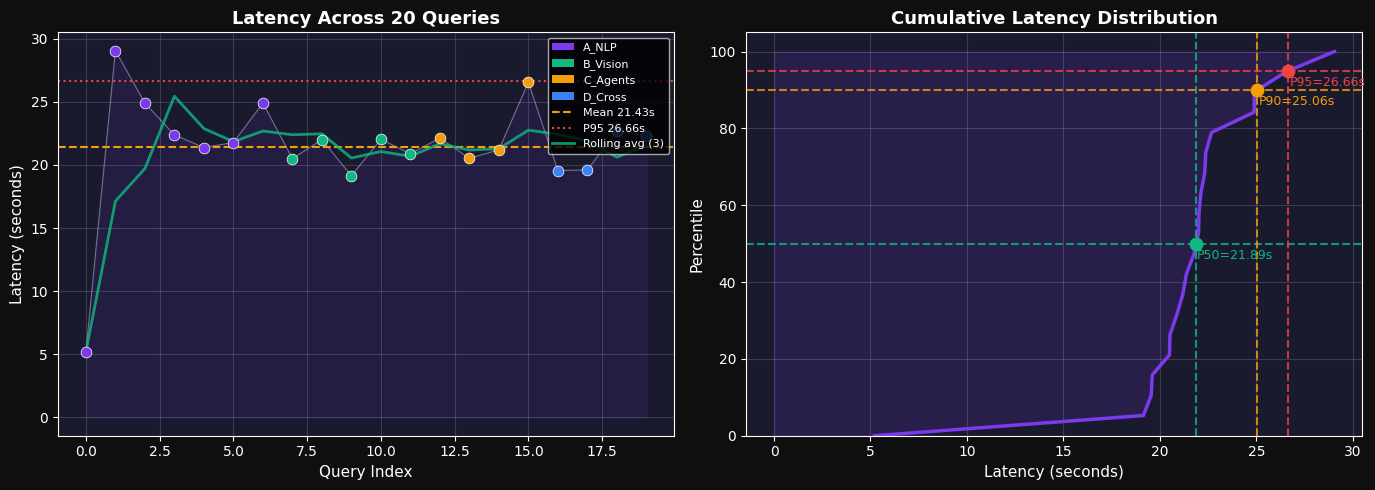

✅ Saved → figures_eval/fig4_latency_stability.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0F0F0F')

ax = axes[0]
ax.set_facecolor('#1A1A2E')

idxs           = range(len(successful))
lats           = successful['latency'].values
tiers          = successful['tier'].values
tier_color_map = {'A_NLP': ACCENT, 'B_Vision': GREEN, 'C_Agents': ORANGE, 'D_Cross': BLUE}

ax.plot(idxs, lats, color='white', linewidth=0.8, alpha=0.4, zorder=1)
ax.fill_between(idxs, lats, alpha=0.1, color=ACCENT)

for i, (lat, tier) in enumerate(zip(lats, tiers)):
    ax.scatter(i, lat, color=tier_color_map.get(tier, 'white'), s=60, zorder=3, edgecolors='white', linewidth=0.5)

ax.axhline(avg_latency, color=ORANGE, linestyle='--', linewidth=1.5, label=f'Mean {avg_latency:.2f}s')
ax.axhline(p95_latency, color=RED,    linestyle=':',  linewidth=1.5, label=f'P95 {p95_latency:.2f}s')

if len(lats) >= 3:
    rolling = pd.Series(lats).rolling(3, min_periods=1).mean().values
    ax.plot(idxs, rolling, color=GREEN, linewidth=2, label='Rolling avg (3)', alpha=0.8)

ax.set_xlabel('Query Index', fontsize=11)
ax.set_ylabel('Latency (seconds)', fontsize=11)
ax.set_title('Latency Across 20 Queries', fontsize=13, fontweight='bold', color='white')
ax.grid(alpha=0.15)

from matplotlib.patches import Patch
tier_legend = [Patch(facecolor=c, label=t) for t, c in tier_color_map.items()]
ax.legend(handles=tier_legend + ax.get_legend_handles_labels()[0],
          labels=list(tier_color_map.keys()) + ax.get_legend_handles_labels()[1],
          fontsize=8, loc='upper right')

ax = axes[1]
ax.set_facecolor('#1A1A2E')

sorted_lats = np.sort(lats)
percentiles = np.linspace(0, 100, len(sorted_lats))

ax.plot(sorted_lats, percentiles, color=ACCENT, linewidth=2.5)
ax.fill_betweenx(percentiles, 0, sorted_lats, alpha=0.15, color=ACCENT)

for pct, color, label in [(50, GREEN, 'P50'), (90, ORANGE, 'P90'), (95, RED, 'P95')]:
    val = np.percentile(lats, pct)
    ax.axvline(val, color=color, linestyle='--', linewidth=1.5, alpha=0.8)
    ax.axhline(pct, color=color, linestyle='--', linewidth=1.5, alpha=0.8)
    ax.scatter(val, pct, color=color, s=80, zorder=5)
    ax.text(val + 0.05, pct - 4, f'{label}={val:.2f}s', color=color, fontsize=9)

ax.set_xlabel('Latency (seconds)', fontsize=11)
ax.set_ylabel('Percentile', fontsize=11)
ax.set_title('Cumulative Latency Distribution', fontsize=13, fontweight='bold', color='white')
ax.grid(alpha=0.15)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig('figures_eval/fig4_latency_stability.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig4_latency_stability.png")

## Cell 9 — Figure 5: Pipeline Performance Dashboard

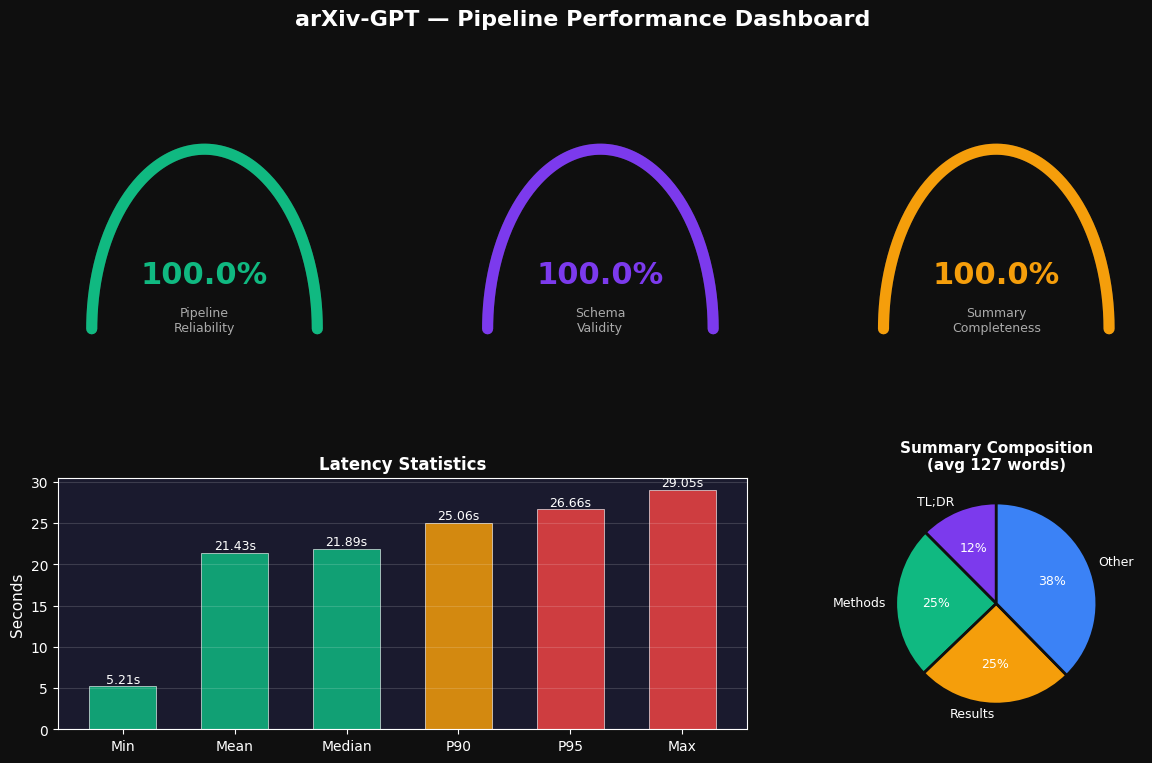

✅ Saved → figures_eval/fig5_performance_dashboard.png


In [14]:
fig = plt.figure(figsize=(14, 8))
fig.patch.set_facecolor('#0F0F0F')
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

theta = np.linspace(0, np.pi, 200)

for ax_idx, (subplot_pos, pct, color, label) in enumerate([
    (gs[0, 0], reliability_pct, GREEN,  'Pipeline\nReliability'),
    (gs[0, 1], schema_valid_rate, ACCENT, 'Schema\nValidity'),
    (gs[0, 2], avg_completeness, ORANGE, 'Summary\nCompleteness'),
]):
    ax = fig.add_subplot(subplot_pos)
    ax.set_facecolor('#1A1A2E')
    ax.plot(np.cos(theta), np.sin(theta), color='#333', linewidth=8, solid_capstyle='round')
    fill_theta = np.linspace(0, np.pi * pct / 100, 200)
    ax.plot(np.cos(fill_theta), np.sin(fill_theta), color=color, linewidth=8, solid_capstyle='round')
    ax.text(0, 0.3, f'{pct:.1f}%', ha='center', va='center', fontsize=22, fontweight='bold', color=color)
    ax.text(0, 0.05, label, ha='center', va='center', fontsize=9, color='#AAA')
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-0.2, 1.2)
    ax.axis('off')

ax4 = fig.add_subplot(gs[1, 0:2])
ax4.set_facecolor('#1A1A2E')
stat_labels = ['Min', 'Mean', 'Median', 'P90', 'P95', 'Max']
stat_values = [min_latency, avg_latency, median_latency, p90_latency, p95_latency, max_latency]
bar_colors  = [GREEN, GREEN, GREEN, ORANGE, RED, RED]
bars = ax4.bar(stat_labels, stat_values, color=bar_colors, alpha=0.85, edgecolor='white', linewidth=0.5, width=0.6)
for bar, val in zip(bars, stat_values):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
             f'{val:.2f}s', ha='center', va='bottom', fontsize=9, color='white')
ax4.set_ylabel('Seconds', fontsize=11)
ax4.set_title('Latency Statistics', fontsize=12, fontweight='bold', color='white')
ax4.grid(alpha=0.15, axis='y')

ax5 = fig.add_subplot(gs[1, 2])
ax5.set_facecolor('#1A1A2E')
tldr_m    = successful['tldr_len'].mean()
methods_m = successful['methods_len'].mean()
results_m = successful['results_len'].mean()
total_m   = successful['total_summary_len'].mean()
other_m   = max(0, total_m - tldr_m - methods_m - results_m)
field_l   = ['TL;DR', 'Methods', 'Results', 'Other']
field_vals_raw = [tldr_m, methods_m, results_m, other_m]
field_vals_filt = [(l, v) for l, v in zip(field_l, field_vals_raw) if v > 0]
f_labels, f_vals = zip(*field_vals_filt)
wedge_c = [ACCENT, GREEN, ORANGE, BLUE][:len(f_vals)]
wedges, texts, autotexts = ax5.pie(f_vals, labels=f_labels, colors=wedge_c,
                                    autopct='%1.0f%%', startangle=90,
                                    wedgeprops=dict(edgecolor='#0F0F0F', linewidth=2))
for text in texts + autotexts:
    text.set_color('white')
    text.set_fontsize(9)
ax5.set_title(f'Summary Composition\n(avg {total_m:.0f} words)', fontsize=11, fontweight='bold', color='white')

fig.suptitle('arXiv-GPT — Pipeline Performance Dashboard', fontsize=16, fontweight='bold', color='white', y=1.01)

plt.savefig('figures_eval/fig5_performance_dashboard.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig5_performance_dashboard.png")

## Cell 10 — Figure 6: Domain-wise Radar Chart

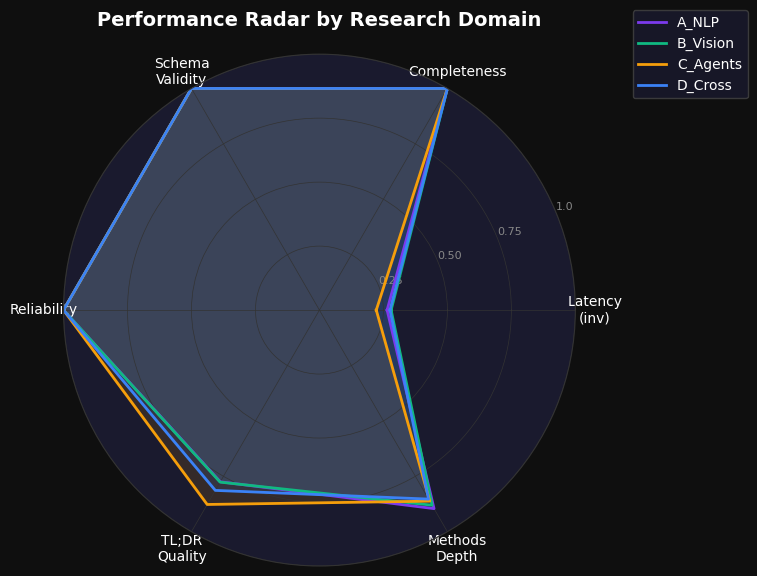

✅ Saved → figures_eval/fig6_radar_chart.png


In [15]:
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'projection': 'polar'})
fig.patch.set_facecolor('#0F0F0F')
ax.set_facecolor('#1A1A2E')

categories = ['Latency\n(inv)', 'Completeness', 'Schema\nValidity', 'Reliability', 'TL;DR\nQuality', 'Methods\nDepth']
N = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

tier_stats = {}
for tier in tier_order:
    t_df = successful[successful['tier'] == tier]
    if len(t_df) == 0:
        continue
    max_lat_all = successful['latency'].max()
    max_tldr    = successful['tldr_len'].max() if successful['tldr_len'].max() > 0 else 1
    max_methods = successful['methods_len'].max() if successful['methods_len'].max() > 0 else 1
    vals = [
        1 - (t_df['latency'].mean() / max_lat_all),
        t_df['completeness'].mean(),
        t_df['schema_valid'].mean(),
        t_df['success'].mean(),
        t_df['tldr_len'].mean() / max_tldr,
        t_df['methods_len'].mean() / max_methods,
    ]
    tier_stats[tier] = vals

for i, (tier, vals) in enumerate(tier_stats.items()):
    vals_plot = vals + [vals[0]]
    color = tier_colors[i % len(tier_colors)]
    ax.plot(angles, vals_plot, color=color, linewidth=2, label=tier)
    ax.fill(angles, vals_plot, color=color, alpha=0.12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=10, color='white')
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0.25', '0.50', '0.75', '1.0'], color='#888', fontsize=8)
ax.grid(color='#333', linewidth=0.5)
ax.spines['polar'].set_color('#333')

ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=10,
          facecolor='#1A1A2E', edgecolor='#444', labelcolor='white')
ax.set_title('Performance Radar by Research Domain', fontsize=14, fontweight='bold', color='white', pad=20)

plt.tight_layout()
plt.savefig('figures_eval/fig6_radar_chart.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig6_radar_chart.png")

## Cell 11 — Figure 7: All Metrics Summary Bar

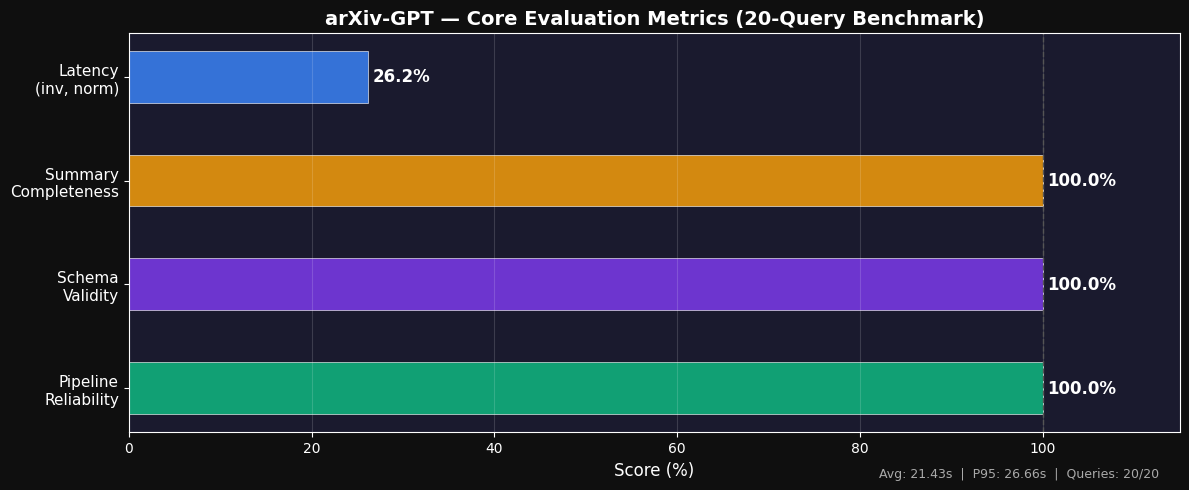

✅ Saved → figures_eval/fig7_metrics_summary.png


In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('#0F0F0F')
ax.set_facecolor('#1A1A2E')

metric_names = ['Pipeline\nReliability', 'Schema\nValidity', 'Summary\nCompleteness', 'Latency\n(inv, norm)']
metric_values = [
    reliability_pct,
    schema_valid_rate,
    avg_completeness,
    (1 - avg_latency / max(lats)) * 100,
]
bar_cols = [GREEN, ACCENT, ORANGE, BLUE]

bars = ax.barh(metric_names, metric_values, color=bar_cols, alpha=0.85,
               edgecolor='white', linewidth=0.5, height=0.5)

for bar, val in zip(bars, metric_values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=12, color='white', fontweight='bold')

ax.axvline(100, color='#555', linestyle='--', linewidth=1)
ax.set_xlim(0, 115)
ax.set_xlabel('Score (%)', fontsize=12)
ax.set_title('arXiv-GPT — Core Evaluation Metrics (20-Query Benchmark)', fontsize=14, fontweight='bold', color='white')
ax.grid(alpha=0.15, axis='x')
ax.tick_params(axis='y', labelsize=11)
ax.text(0.98, -0.12, f'Avg: {avg_latency:.2f}s  |  P95: {p95_latency:.2f}s  |  Queries: {n_success}/20',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=9, color='#AAA')

plt.tight_layout()
plt.savefig('figures_eval/fig7_metrics_summary.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig7_metrics_summary.png")

## Cell 12 — Tier-wise Latency Breakdown Table
> Detailed per-domain latency statistics: mean, median, std, min, max, P90, P95.

In [17]:
tier_latency = df.groupby('tier')['latency'].agg([
    'count',
    'mean',
    'median',
    'std',
    'min',
    'max',
    lambda x: x.quantile(0.90),
    lambda x: x.quantile(0.95)
]).round(2)

tier_latency.columns = [
    'count', 'mean_latency', 'median_latency', 'std_latency',
    'min_latency', 'max_latency', 'p90_latency', 'p95_latency'
]

print("📊 Tier-wise Latency Breakdown:")
print(tier_latency.to_string())
tier_latency

📊 Tier-wise Latency Breakdown:
          count  mean_latency  median_latency  std_latency  min_latency  max_latency  p90_latency  p95_latency
tier                                                                                                          
A_NLP         7         21.37           22.38         7.60         5.21        29.05        26.56        27.80
B_Vision      5         20.91           20.88         1.20        19.14        22.03        22.02        22.02
C_Agents      4         22.59           21.66         2.71        20.52        26.54        25.21        25.87
D_Cross       4         21.04           20.96         1.69        19.55        22.68        22.57        22.62


,count,mean_latency,median_latency,std_latency,min_latency,max_latency,p90_latency,p95_latency
tier,,,,,,,,
A_NLP,7,21.37,22.38,7.60,5.21,29.05,26.56,27.80
B_Vision,5,20.91,20.88,1.20,19.14,22.03,22.02,22.02
C_Agents,4,22.59,21.66,2.71,20.52,26.54,25.21,25.87
D_Cross,4,21.04,20.96,1.69,19.55,22.68,22.57,22.62


## Cell 13 — Variance & Correlation Analysis
> Latency variance, summary length variance, and latency-vs-length correlation (global + per tier).

In [18]:
# ─── Global variance ───
latency_variance = df['latency'].var().round(2)
latency_std_g    = df['latency'].std().round(2)
length_variance  = df['total_summary_len'].var().round(2)
length_std_g     = df['total_summary_len'].std().round(2)

# ─── Latency vs Length correlation ───
global_corr = df['latency'].corr(df['total_summary_len']).round(3)

# ─── Tier-wise correlation ───
tier_corr = (
    df.groupby('tier')
      .apply(lambda x: x['latency'].corr(x['total_summary_len']))
      .round(3)
)

# ─── Combined tier metrics ───
tier_metrics = df.groupby('tier').agg({
    'latency':          ['mean', 'median', 'std', lambda x: x.quantile(0.95)],
    'total_summary_len': ['mean', 'std']
}).round(2)

print("╔══════════════════════════════════════════════════════╗")
print("║          Variance & Correlation Analysis             ║")
print("╠══════════════════════════════════════════════════════╣")
print(f"║  Latency Variance     :  {latency_variance:<10}                ║")
print(f"║  Latency Std Dev      :  {latency_std_g:<10}                ║")
print(f"║  Length Variance      :  {length_variance:<10}                ║")
print(f"║  Length Std Dev       :  {length_std_g:<10}                ║")
print(f"║  Latency-Length Corr  :  {global_corr:<10}                ║")
print("╚══════════════════════════════════════════════════════╝")

print("\n📊 Tier-wise Latency vs Length Correlation:")
print(tier_corr.to_string())

print("\n📊 Combined Tier Metrics:")
print(tier_metrics.to_string())

╔══════════════════════════════════════════════════════╗
║          Variance & Correlation Analysis             ║
╠══════════════════════════════════════════════════════╣
║  Latency Variance     :  20.52                     ║
║  Latency Std Dev      :  4.53                      ║
║  Length Variance      :  90.67                     ║
║  Length Std Dev       :  9.52                      ║
║  Latency-Length Corr  :  0.059                     ║
╚══════════════════════════════════════════════════════╝

📊 Tier-wise Latency vs Length Correlation:
tier
A_NLP      -0.300
B_Vision    0.685
C_Agents    0.666
D_Cross     0.406

📊 Combined Tier Metrics:
         latency                         total_summary_len       
            mean median   std <lambda_0>              mean    std
tier                                                             
A_NLP      21.37  22.38  7.60      27.80            127.62   6.64
B_Vision   20.91  20.88  1.20      22.02            126.60   3.63
C_Agents   22.59  21

## Cell 14 — Figure 8: Tier Latency Breakdown Visualization

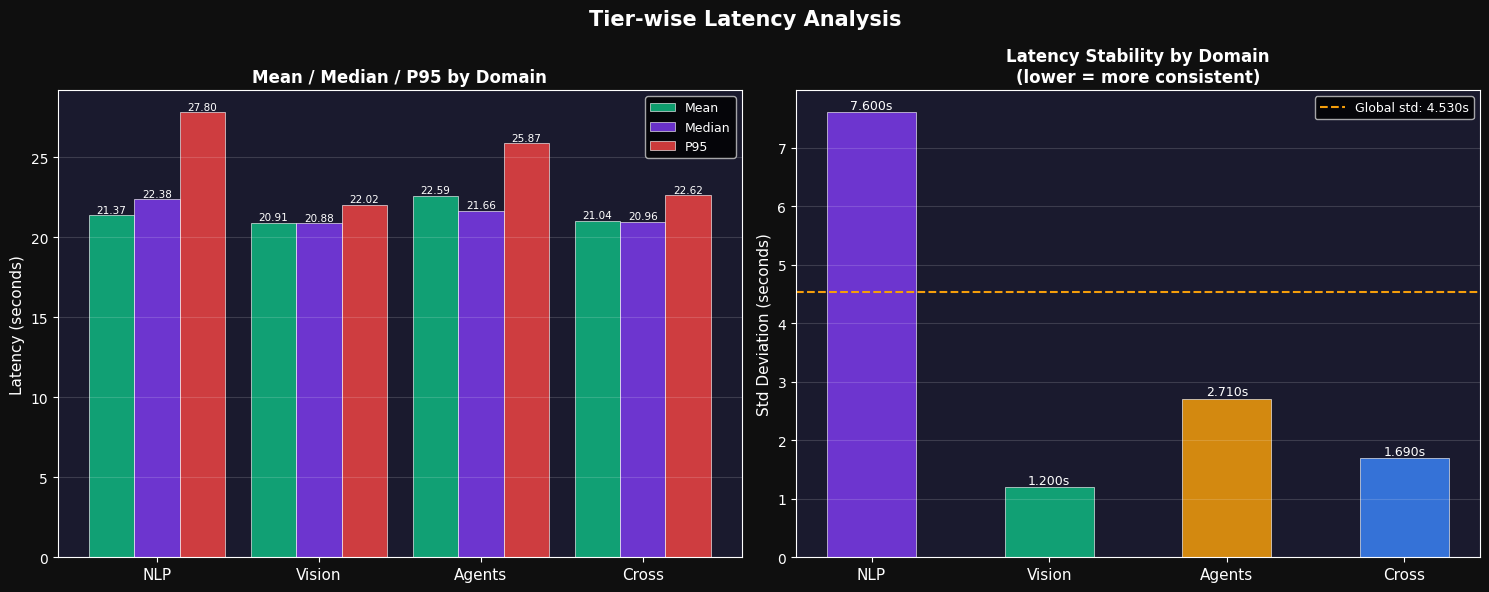

✅ Saved → figures_eval/fig8_tier_latency_breakdown.png


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor('#0F0F0F')
fig.suptitle('Tier-wise Latency Analysis', fontsize=15, fontweight='bold', color='white')

# ─── Left: Grouped bar — mean + P95 per tier ───
ax = axes[0]
ax.set_facecolor('#1A1A2E')

tiers_present = [t for t in tier_order if t in tier_latency.index]
x = np.arange(len(tiers_present))
width = 0.28

mean_vals   = [tier_latency.loc[t, 'mean_latency']   for t in tiers_present]
median_vals = [tier_latency.loc[t, 'median_latency'] for t in tiers_present]
p95_vals    = [tier_latency.loc[t, 'p95_latency']    for t in tiers_present]

b1 = ax.bar(x - width, mean_vals,   width, label='Mean',   color=GREEN,  alpha=0.85, edgecolor='white', linewidth=0.5)
b2 = ax.bar(x,         median_vals, width, label='Median', color=ACCENT, alpha=0.85, edgecolor='white', linewidth=0.5)
b3 = ax.bar(x + width, p95_vals,    width, label='P95',    color=RED,    alpha=0.85, edgecolor='white', linewidth=0.5)

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.03, f'{h:.2f}',
                ha='center', va='bottom', fontsize=7.5, color='white')

ax.set_xticks(x)
ax.set_xticklabels([t.split('_')[1] for t in tiers_present], fontsize=11)
ax.set_ylabel('Latency (seconds)', fontsize=11)
ax.set_title('Mean / Median / P95 by Domain', fontsize=12, fontweight='bold', color='white')
ax.legend(fontsize=9)
ax.grid(alpha=0.15, axis='y')

# ─── Right: Std deviation (stability) per tier ───
ax = axes[1]
ax.set_facecolor('#1A1A2E')

std_vals  = [tier_latency.loc[t, 'std_latency'] for t in tiers_present]
bar_c     = tier_colors[:len(tiers_present)]
bars      = ax.bar(range(len(tiers_present)), std_vals, color=bar_c, alpha=0.85,
                   edgecolor='white', linewidth=0.5, width=0.5)

for bar, val in zip(bars, std_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}s', ha='center', va='bottom', fontsize=9, color='white')

ax.set_xticks(range(len(tiers_present)))
ax.set_xticklabels([t.split('_')[1] for t in tiers_present], fontsize=11)
ax.set_ylabel('Std Deviation (seconds)', fontsize=11)
ax.set_title('Latency Stability by Domain\n(lower = more consistent)', fontsize=12, fontweight='bold', color='white')
ax.grid(alpha=0.15, axis='y')

# Annotate global std
ax.axhline(latency_std_g, color=ORANGE, linestyle='--', linewidth=1.5, label=f'Global std: {latency_std_g:.3f}s')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('figures_eval/fig8_tier_latency_breakdown.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig8_tier_latency_breakdown.png")

## Cell 15 — Figure 9: Latency vs Summary Length Scatter + Correlation

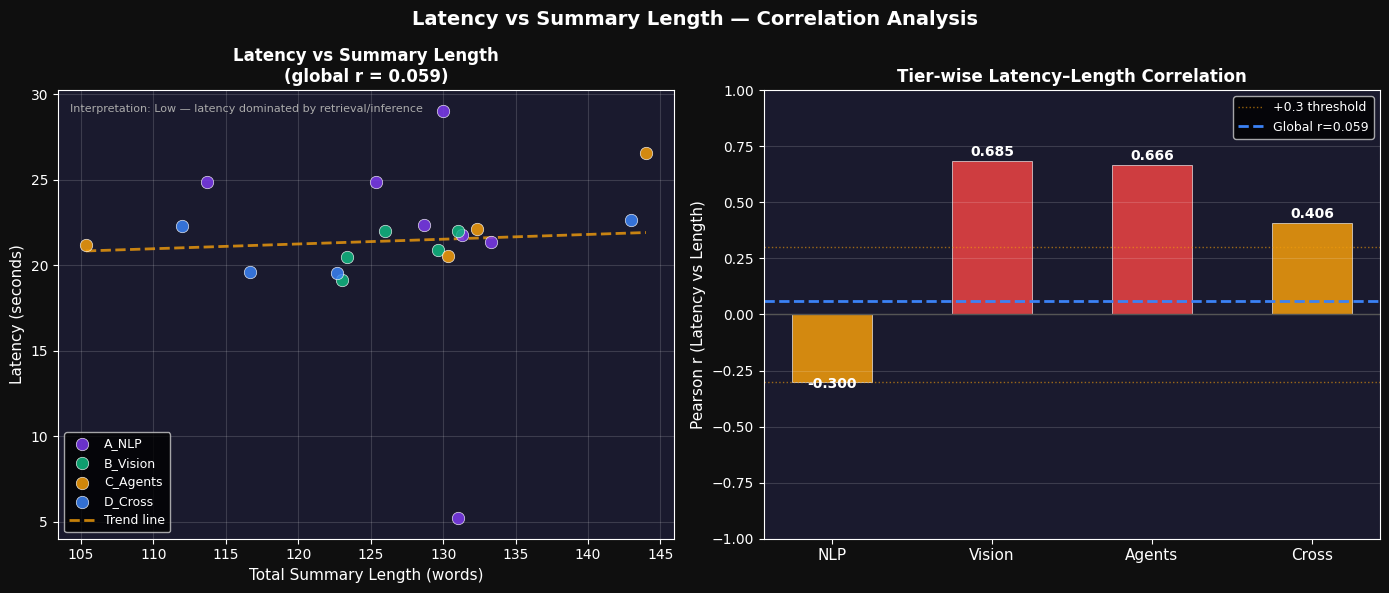

✅ Saved → figures_eval/fig9_latency_length_correlation.png


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('#0F0F0F')
fig.suptitle('Latency vs Summary Length — Correlation Analysis', fontsize=14, fontweight='bold', color='white')

# ─── Left: Scatter — all queries colored by tier ───
ax = axes[0]
ax.set_facecolor('#1A1A2E')

for tier, color in zip(tier_order, tier_colors):
    t_df = successful[successful['tier'] == tier]
    if len(t_df) == 0:
        continue
    ax.scatter(t_df['total_summary_len'], t_df['latency'],
               color=color, s=80, alpha=0.85, label=tier,
               edgecolors='white', linewidth=0.5, zorder=3)

# Global trend line
x_vals = successful['total_summary_len'].values
y_vals = successful['latency'].values
if len(x_vals) > 1:
    z = np.polyfit(x_vals, y_vals, 1)
    p = np.poly1d(z)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
    ax.plot(x_line, p(x_line), color=ORANGE, linewidth=2, linestyle='--', alpha=0.8, label='Trend line')

ax.set_xlabel('Total Summary Length (words)', fontsize=11)
ax.set_ylabel('Latency (seconds)', fontsize=11)
ax.set_title(f'Latency vs Summary Length\n(global r = {global_corr:.3f})', fontsize=12, fontweight='bold', color='white')
ax.legend(fontsize=9)
ax.grid(alpha=0.15)

# Correlation interpretation
interp = 'Low — latency dominated by retrieval/inference' if abs(global_corr) < 0.3 else \
         'Moderate correlation' if abs(global_corr) < 0.6 else 'High correlation'
ax.text(0.02, 0.97, f'Interpretation: {interp}', transform=ax.transAxes,
        fontsize=8, color='#AAA', va='top')

# ─── Right: Tier-wise correlation bar chart ───
ax = axes[1]
ax.set_facecolor('#1A1A2E')

tiers_corr    = [t for t in tier_order if t in tier_corr.index]
corr_vals     = [tier_corr[t] for t in tiers_corr]
colors_corr   = [GREEN if abs(v) < 0.3 else ORANGE if abs(v) < 0.6 else RED for v in corr_vals]

bars = ax.bar(range(len(tiers_corr)), corr_vals, color=colors_corr,
              alpha=0.85, edgecolor='white', linewidth=0.5, width=0.5)

for bar, val in zip(bars, corr_vals):
    ypos = bar.get_height() + 0.01 if val >= 0 else bar.get_height() - 0.04
    ax.text(bar.get_x() + bar.get_width()/2, ypos,
            f'{val:.3f}', ha='center', va='bottom', fontsize=10, color='white', fontweight='bold')

ax.axhline(0,    color='#555', linewidth=1)
ax.axhline( 0.3, color=ORANGE, linewidth=1, linestyle=':', alpha=0.6, label='+0.3 threshold')
ax.axhline(-0.3, color=ORANGE, linewidth=1, linestyle=':', alpha=0.6)
ax.axhline(global_corr, color=BLUE, linewidth=2, linestyle='--', label=f'Global r={global_corr:.3f}')

ax.set_xticks(range(len(tiers_corr)))
ax.set_xticklabels([t.split('_')[1] for t in tiers_corr], fontsize=11)
ax.set_ylabel('Pearson r (Latency vs Length)', fontsize=11)
ax.set_title('Tier-wise Latency–Length Correlation', fontsize=12, fontweight='bold', color='white')
ax.set_ylim(-1, 1)
ax.legend(fontsize=9)
ax.grid(alpha=0.15, axis='y')

plt.tight_layout()
plt.savefig('figures_eval/fig9_latency_length_correlation.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig9_latency_length_correlation.png")

## Cell 16 — Figure 10: Variance & Stability Dashboard

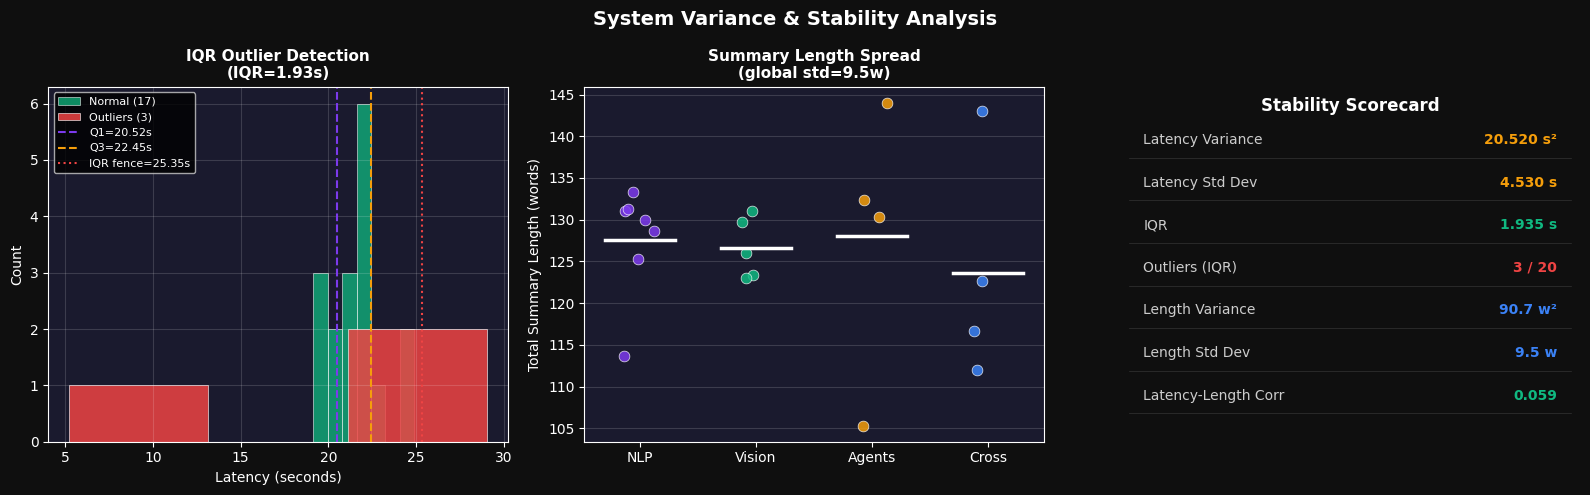

✅ Saved → figures_eval/fig10_variance_stability.png


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor('#0F0F0F')
fig.suptitle('System Variance & Stability Analysis', fontsize=14, fontweight='bold', color='white')

# ─── Left: Latency IQR + outlier detection ───
ax = axes[0]
ax.set_facecolor('#1A1A2E')

lats_all = df['latency'].values
q1   = np.percentile(lats_all, 25)
q3   = np.percentile(lats_all, 75)
iqr  = q3 - q1
low_fence  = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
outliers   = lats_all[(lats_all < low_fence) | (lats_all > high_fence)]
normal     = lats_all[(lats_all >= low_fence) & (lats_all <= high_fence)]

ax.hist(normal,   bins=7, color=GREEN,  alpha=0.75, edgecolor='white', linewidth=0.5, label=f'Normal ({len(normal)})')
ax.hist(outliers, bins=3, color=RED,    alpha=0.85, edgecolor='white', linewidth=0.5, label=f'Outliers ({len(outliers)})') if len(outliers) > 0 else None
ax.axvline(q1,          color=ACCENT, linestyle='--', linewidth=1.5, label=f'Q1={q1:.2f}s')
ax.axvline(q3,          color=ORANGE, linestyle='--', linewidth=1.5, label=f'Q3={q3:.2f}s')
ax.axvline(high_fence,  color=RED,    linestyle=':',  linewidth=1.5, label=f'IQR fence={high_fence:.2f}s')
ax.set_xlabel('Latency (seconds)', fontsize=10)
ax.set_ylabel('Count', fontsize=10)
ax.set_title(f'IQR Outlier Detection\n(IQR={iqr:.2f}s)', fontsize=11, fontweight='bold', color='white')
ax.legend(fontsize=8)
ax.grid(alpha=0.15)

# ─── Middle: Summary length distribution per tier ───
ax = axes[1]
ax.set_facecolor('#1A1A2E')

tiers_present = [t for t in tier_order if t in df['tier'].values]
for i, (tier, color) in enumerate(zip(tiers_present, tier_colors)):
    t_df = df[df['tier'] == tier]
    ax.scatter(np.full(len(t_df), i) + np.random.uniform(-0.15, 0.15, len(t_df)),
               t_df['total_summary_len'],
               color=color, alpha=0.85, s=60, edgecolors='white', linewidth=0.5, zorder=3)
    mean_val = t_df['total_summary_len'].mean()
    ax.plot([i - 0.3, i + 0.3], [mean_val, mean_val], color='white', linewidth=2.5, zorder=4)

ax.set_xticks(range(len(tiers_present)))
ax.set_xticklabels([t.split('_')[1] for t in tiers_present], fontsize=10)
ax.set_ylabel('Total Summary Length (words)', fontsize=10)
ax.set_title(f'Summary Length Spread\n(global std={length_std_g:.1f}w)', fontsize=11, fontweight='bold', color='white')
ax.grid(alpha=0.15, axis='y')

# ─── Right: Variance summary scorecards ───
ax = axes[2]
ax.set_facecolor('#1A1A2E')
ax.axis('off')

scorecard_lines = [
    ('Latency Variance',        f'{latency_variance:.3f} s²',      ORANGE),
    ('Latency Std Dev',         f'{latency_std_g:.3f} s',          ORANGE),
    ('IQR',                     f'{iqr:.3f} s',                    GREEN),
    ('Outliers (IQR)',          f'{len(outliers)} / {len(lats_all)}', RED if len(outliers) > 2 else GREEN),
    ('Length Variance',         f'{length_variance:.1f} w²',       BLUE),
    ('Length Std Dev',          f'{length_std_g:.1f} w',           BLUE),
    ('Latency-Length Corr',     f'{global_corr:.3f}',              GREEN if abs(global_corr) < 0.3 else ORANGE),
]

ax.text(0.5, 0.97, 'Stability Scorecard', ha='center', va='top',
        fontsize=12, fontweight='bold', color='white', transform=ax.transAxes)

for i, (label, val, color) in enumerate(scorecard_lines):
    y = 0.85 - i * 0.12
    ax.text(0.05, y, label,  ha='left',  va='center', fontsize=10, color='#CCC', transform=ax.transAxes)
    ax.text(0.95, y, val,    ha='right', va='center', fontsize=10, color=color,  transform=ax.transAxes, fontweight='bold')
    ax.plot([0.02, 0.98], [y - 0.05, y - 0.05],
        color='#333', linewidth=0.5,
        transform=ax.transAxes)

plt.tight_layout()
plt.savefig('figures_eval/fig10_variance_stability.png', dpi=150, bbox_inches='tight', facecolor='#0F0F0F')
plt.show()
print("✅ Saved → figures_eval/fig10_variance_stability.png")

## Cell 17 — Export & Final Report

In [22]:
metrics_path = BASE_DIR / "eval_metrics.json"

final_metrics = {
    "timestamp":             datetime.now().isoformat(),
    "n_queries":             len(df),
    "n_successful":          int(n_success),
    "pipeline_reliability":  round(reliability_pct, 1),
    "schema_validity":       round(schema_valid_rate, 1),
    "avg_completeness":      round(avg_completeness, 1),
    "latency": {
        "avg":      round(avg_latency, 2),
        "median":   round(median_latency, 2),
        "p90":      round(p90_latency, 2),
        "p95":      round(p95_latency, 2),
        "std":      round(std_latency, 2),
        "variance": round(latency_variance, 3),
        "iqr":      round(float(iqr), 3),
        "min":      round(float(min_latency), 2),
        "max":      round(float(max_latency), 2),
        "outliers_iqr": int(len(outliers)),
    },
    "summary_quality": {
        "avg_tldr_words":    round(avg_tldr_len, 1),
        "avg_methods_words": round(avg_methods_len, 1),
        "avg_results_words": round(avg_results_len, 1),
        "avg_total_words":   round(avg_total_summary, 1),
        "length_variance":   round(length_variance, 1),
        "length_std":        round(length_std_g, 1),
    },
    "correlation": {
        "latency_vs_length_global": float(global_corr),
        "latency_vs_length_by_tier": {k: round(float(v), 3) for k, v in tier_corr.items()},
    },
    "tier_latency": tier_latency.to_dict()
}

with open(metrics_path, "w") as f:
    json.dump(final_metrics, f, indent=2)

# ─── Updated CSV with variance columns ───
df.to_csv(csv_path, index=False)

print("╔════════════════════════════════════════════════════════════╗")
print("║        📋 arXiv-GPT — Resume-Ready Benchmark Numbers      ║")
print("╠════════════════════════════════════════════════════════════╣")
print(f"║  Avg End-to-End Latency         :  {avg_latency:.2f}s                   ║")
print(f"║  P95 Latency                    :  {p95_latency:.2f}s                   ║")
print(f"║  Latency Std Dev                :  {latency_std_g:.3f}s                  ║")
print(f"║  Pipeline Reliability           :  {reliability_pct:.0f}%                      ║")
print(f"║  Structured Summary Completeness:  {avg_completeness:.0f}%                      ║")
print(f"║  Schema Validity                :  {schema_valid_rate:.0f}%                      ║")
print(f"║  Latency-Length Correlation     :  {global_corr:.3f}                   ║")
print("╠════════════════════════════════════════════════════════════╣")
print("║  Evaluation: 20 queries × 4 domains                       ║")
print("╚════════════════════════════════════════════════════════════╝")

print("\n📁 Saved Data:")
print(f"   ✅ {csv_path.name}")
print(f"   ✅ {metrics_path.name}")

print("\n📊 Saved Figures:")
for f_name in sorted(os.listdir(FIGURES_DIR)):
    if f_name.endswith(".png"):
        print(f"   ✅ figures_eval/{f_name}")

╔════════════════════════════════════════════════════════════╗
║        📋 arXiv-GPT — Resume-Ready Benchmark Numbers      ║
╠════════════════════════════════════════════════════════════╣
║  Avg End-to-End Latency         :  21.43s                   ║
║  P95 Latency                    :  26.66s                   ║
║  Latency Std Dev                :  4.530s                  ║
║  Pipeline Reliability           :  100%                      ║
║  Structured Summary Completeness:  100%                      ║
║  Schema Validity                :  100%                      ║
║  Latency-Length Correlation     :  0.059                   ║
╠════════════════════════════════════════════════════════════╣
║  Evaluation: 20 queries × 4 domains                       ║
╚════════════════════════════════════════════════════════════╝

📁 Saved Data:
   ✅ eval_results.csv
   ✅ eval_metrics.json

📊 Saved Figures:
   ✅ figures_eval/fig10_variance_stability.png
   ✅ figures_eval/fig1_latency_distribution.png
   